In [3]:
# Install emcee
!pip install emcee -q

In [4]:
# Import the packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import emcee

from scipy.optimize import curve_fit
from google.colab import files

uploaded = files.upload()

Saving ito_data.csv to ito_data.csv


In [5]:
# Read the catalogue
df = pd.read_csv("ito_data.csv")

# Check the first few rows
df.head()

# Check the column names
print(df.columns.tolist())

['ID', 'z_phot', 'logMstar', 'Re_05um_kpc', 'Re_05um_err_kpc', 'Re_F277W_kpc', 'Re_F277W_err_kpc', 'gamma', 'gamma_err', 'Nfilter', 'flag']


Full sample: 26
Fitting sample: 22
Mass range: 10.34 to 11.39
Redshift range: 2.83 to 4.63


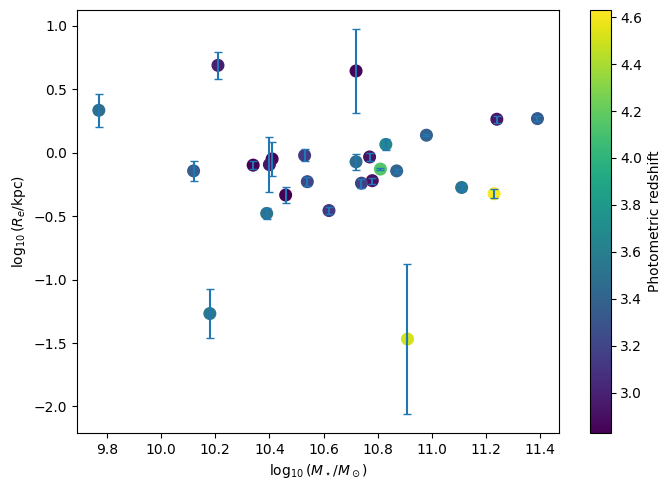

In [8]:
# Section 1: Data from Catalogue

# Convert to log10(R_e)
df["logRe_05um"] = np.log10(df["Re_05um_kpc"])

# Convert the radius uncertainty into log
df["logRe_05um_err"] = (df["Re_05um_err_kpc"]/(df["Re_05um_kpc"] * np.log(10)))

# Make the stellar-mass cut
fit_df = df[df["logMstar"] > 10.3].copy()

# Create arrays
x = fit_df["logMstar"].to_numpy() # mass
y = fit_df["logRe_05um"].to_numpy() # radius
yerr = fit_df["logRe_05um_err"].to_numpy() # radius error
z = fit_df["z_phot"].to_numpy() # photometric redshift

# Check the sample
print("Full sample:", len(df))
print("Fitting sample:", len(fit_df))
print("Mass range:", x.min(), "to", x.max())
print("Redshift range:", z.min(), "to", z.max())

# Plot the 26 galaxy size-mass distribution
plt.figure(figsize=(7, 5))

plt.errorbar(
    df["logMstar"],
    df["logRe_05um"],
    yerr=df["logRe_05um_err"],
    fmt="none",
    capsize=3 )

# Colour galaxies by photometric redshift
sc = plt.scatter(
    df["logMstar"],
    df["logRe_05um"],
    c=df["z_phot"],
    s=70 )

plt.xlabel(r"$\log_{10}(M_\star/M_\odot)$")
plt.ylabel(r"$\log_{10}(R_e/\mathrm{kpc})$")

cbar = plt.colorbar(sc)
cbar.set_label("Photometric redshift")

plt.tight_layout()
plt.show()

a = -0.152 ± 0.007
b = 0.571 ± 0.021


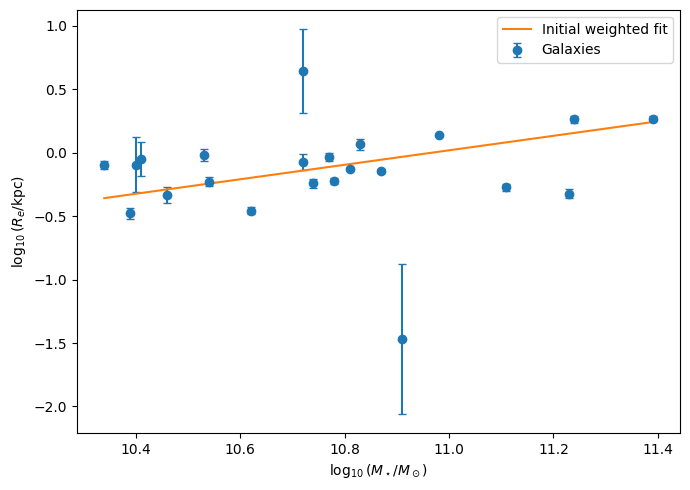

In [9]:
# Section 2: Initial size-mass fit

# Define the size-mass relation
def size_mass_model(logM, a, b):
    return a + b * (logM - 10.7)
    # a-normalization, b-slope, 10.7-reference mass

# Fit the 22 galaxies above the mass cut
popt, pcov = curve_fit(
    size_mass_model,
    x,
    y,
    sigma=yerr,
    absolute_sigma=True)

# Best-fit values
a_curve, b_curve = popt

# Uncertainties from the covariance matrix
a_curve_err, b_curve_err = np.sqrt(np.diag(pcov))

# Print the results
print(f"a = {a_curve:.3f} ± {a_curve_err:.3f}")
print(f"b = {b_curve:.3f} ± {b_curve_err:.3f}")

# Create fitted line
x_line = np.linspace(x.min(), x.max(), 200)
y_line = size_mass_model(x_line, a_curve, b_curve)

# Plot the fitting sample and initial fit
plt.figure(figsize=(7, 5))

plt.errorbar(
    x,
    y,
    yerr=yerr,
    fmt="o",
    capsize=3,
    label="Galaxies")

plt.plot(
    x_line,
    y_line,
    label="Initial weighted fit")

plt.xlabel(r"$\log_{10}(M_\star/M_\odot)$")
plt.ylabel(r"$\log_{10}(R_e/\mathrm{kpc})$")

plt.legend()
plt.tight_layout()
plt.show()

100%|██████████| 6000/6000 [00:10<00:00, 583.33it/s]


Mean acceptance fraction: 0.6441458333333333

Autocorrelation times:
a: 38.824017070938496
b: 37.417041378157464
sigma_int: 36.53227829004483

MCMC RESULTS
a = -0.145 -0.049 +0.049
b = 0.319 -0.165 +0.162
intrinsic scatter = 0.190 -0.041 +0.050


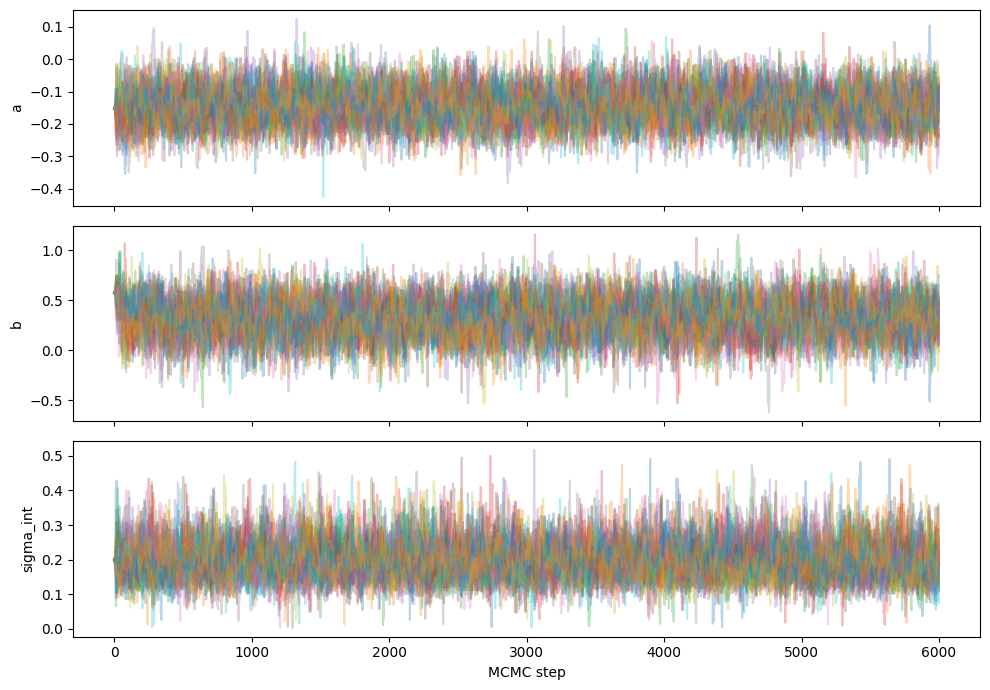

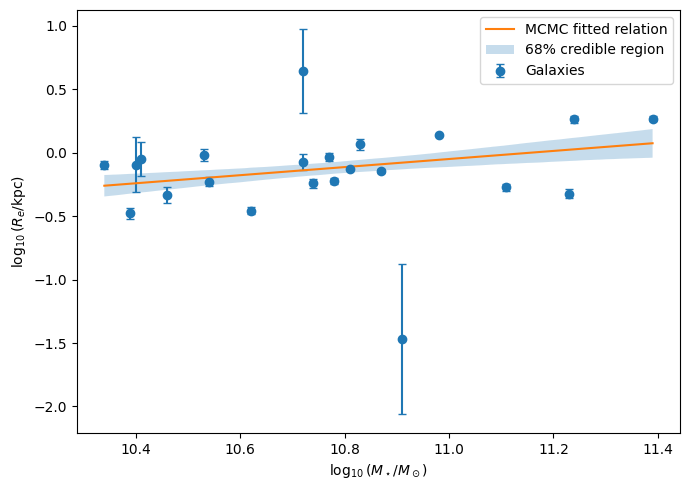

In [10]:
# Section 3: MCMC size-mass fit

# Stellar-mass uncertainty used in the fit
mass_err = 0.21

# Prior: allowed ranges for a, b, and intrinsic scatter
def log_prior(theta):
    a, b, sigma_int = theta
    if -2 < a < 1 and -2 < b < 2 and 0 < sigma_int < 1:
        return 0.0
    return -np.inf


# Likelihood: checks how well a set of parameters matches the data
def log_likelihood(theta, x, y, yerr):
    a, b, sigma_int = theta
    model = a + b * (x - 10.7) # calculates galaxy size given by a set

    # Total uncertainty:
    # radius measurement error
    # stellar-mass uncertainty
    # intrinsic galaxy-to-galaxy scatter
    variance = ( yerr**2 + (b * mass_err)**2 + sigma_int**2 )

    return -0.5 * np.sum((y - model)**2 / variance + np.log(2 * np.pi * variance))
    # Large likelihood-> better fit

# Combine the prior and likelihood
def log_probability(theta, x, y, yerr):
    lp = log_prior(theta)

    if not np.isfinite(lp):
        return -np.inf
    return lp + log_likelihood(theta, x, y, yerr)

# Starting values based on the initial fit
initial_guess = np.array([
    a_curve,
    b_curve,
    0.2]) # intrinsic scatter = 0.2

# MCMC settings
ndim = 3 # a,b,sigma
nwalkers = 32 # searches
nsteps = 6000 # steps each walker takes
burnin = 1500 # discarded initial steps

# Give each walker a different starting position
np.random.seed(42)
pos = (initial_guess + 1e-3 * np.random.randn(nwalkers, ndim))
  # starts walkers very close to the initial best-fit

# Run the MCMC
sampler = emcee.EnsembleSampler(
    nwalkers,
    ndim,
    log_probability,
    args=(x, y, yerr))

sampler.run_mcmc(pos, nsteps, progress=True)

# Check the mean acceptance fraction
print("Mean acceptance fraction:", np.mean(sampler.acceptance_fraction))
  # checks how often the walkers accept the moves

# Check the autocorrelation times
tau = sampler.get_autocorr_time(tol=0)
  # estimates how many steps until MCMC samples become independent of the previous ones

print("\nAutocorrelation times:")
print("a:", tau[0])
print("b:", tau[1])
print("sigma_int:", tau[2])

# Remove burn-in and combine all walkers
flat_samples = sampler.get_chain(discard=burnin, flat=True)
  # removes the first 1500 steps

a_samples = flat_samples[:, 0]
b_samples = flat_samples[:, 1]
sigma_samples = flat_samples[:, 2]

# Function to get the median and 68% credible interval
def get_result(samples):
    q16, q50, q84 = np.percentile(samples, [16, 50, 84])

    return (q50, q50 - q16, q84 - q50) # percentiles

# Final parameter values
a_med, a_low, a_high = get_result(a_samples)
b_med, b_low, b_high = get_result(b_samples)
s_med, s_low, s_high = get_result(sigma_samples)

print("\nMCMC RESULTS")
print("a =", f"{a_med:.3f}", f"-{a_low:.3f}", f"+{a_high:.3f}")
print("b =", f"{b_med:.3f}", f"-{b_low:.3f}", f"+{b_high:.3f}")
print("intrinsic scatter =", f"{s_med:.3f}", f"-{s_low:.3f}", f"+{s_high:.3f}")

# Trace plots to check that the chains are stable
samples = sampler.get_chain()

fig, axes = plt.subplots(3, figsize=(10, 7), sharex=True)

labels = ["a", "b", "sigma_int"]

for i in range(3):
    axes[i].plot(samples[:, :, i], alpha=0.3)
    axes[i].set_ylabel(labels[i])

axes[-1].set_xlabel("MCMC step")

plt.tight_layout()
plt.show()

# Final MCMC size-mass relation
x_line = np.linspace(x.min(), x.max(), 200)
y_line_mcmc = (a_med + b_med * (x_line - 10.7))

# Create a 68% credible region from posterior samples
model_samples = []

for a_s, b_s in zip(a_samples[::50], b_samples[::50]):
    model_samples.append(a_s + b_s * (x_line - 10.7))

model_samples = np.array(model_samples)

lower_band = np.percentile(model_samples, 16, axis=0)
upper_band = np.percentile(model_samples, 84, axis=0)

# Plot the final size-mass MCMC fit
plt.figure(figsize=(7, 5))

plt.errorbar(
    x,
    y,
    yerr=yerr,
    fmt="o",
    capsize=3,
    label="Galaxies")

plt.plot(
    x_line,
    y_line_mcmc,
    label="MCMC fitted relation")

plt.fill_between(
    x_line,
    lower_band,
    upper_band,
    alpha=0.25,
    label="68% credible region")

plt.xlabel(r"$\log_{10}(M_\star/M_\odot)$")
plt.ylabel(r"$\log_{10}(R_e/\mathrm{kpc})$")

plt.legend()
plt.tight_layout()
plt.show()

100%|██████████| 6000/6000 [00:11<00:00, 530.21it/s]


Mean acceptance fraction: 0.5941458333333334

Autocorrelation times:
a: 49.375752896451786
b: 45.429835095022526
c: 48.76369749060018
sigma_int: 45.46889377103937

FULL MCMC RESULTS
a = -0.159 -0.043 +0.044
b = 0.530 -0.166 +0.161
c = -0.272 -0.106 +0.099
intrinsic scatter = 0.139 -0.058 +0.055

95% credible interval for c:
-0.499 to -0.075

Probability that c < 0:
0.9959
Percentage of posterior with c < 0: 99.59%


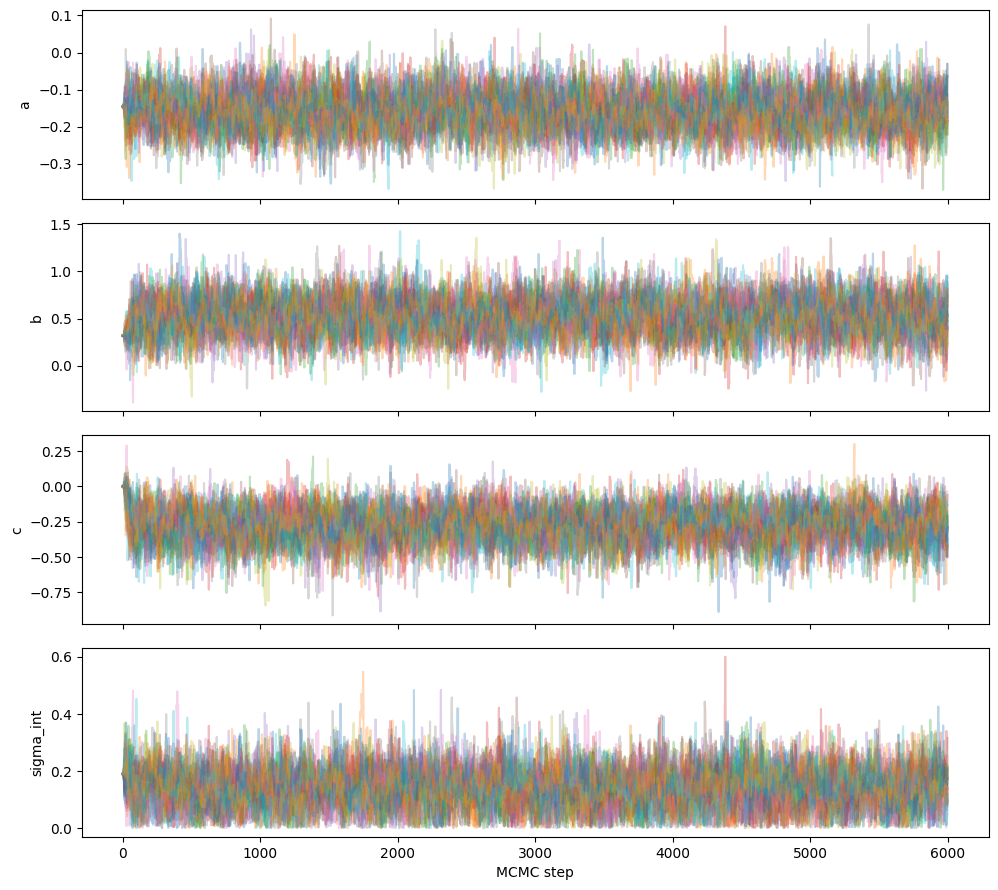

In [11]:
# Section 4: MCMC with redshift

# Define the full model with stellar mass and redshift
def full_model(logM, z, a, b, c):
    return (a + b * (logM - 10.7) + c * (z - 3.3))

# Prior for a, b, c, and intrinsic scatter
def log_prior_full(theta):
    a, b, c, sigma_int = theta

    if (-2 < a < 1 and -2 < b < 2 and -2 < c < 2 and 0 < sigma_int < 1):
        return 0.0
    return -np.inf

# Likelihood for the full model
def log_likelihood_full(theta, x, z, y, yerr):
    a, b, c, sigma_int = theta
    model = full_model(x, z, a, b, c)

    # Total uncertainty includes:
    # radius measurement error
    # stellar-mass uncertainty
    # intrinsic scatter
    variance = (yerr**2 + (b * mass_err)**2 + sigma_int**2)
    return -0.5 * np.sum((y - model)**2 / variance + np.log(2 * np.pi * variance))

# Combine the prior and likelihood
def log_probability_full(theta, x, z, y, yerr):
    lp = log_prior_full(theta)

    if not np.isfinite(lp):
        return -np.inf

    return lp + log_likelihood_full(theta, x, z, y, yerr)


# Starting values
initial_guess_full = np.array([a_med, b_med, 0.0, s_med])

# MCMC settings
ndim_full = 4
nwalkers_full = 32
nsteps_full = 6000
burnin_full = 1500

# Give each walker a different starting position
np.random.seed(42)

pos_full = (initial_guess_full + 1e-3 * np.random.randn(nwalkers_full, ndim_full))

# Run the MCMC
sampler_full = emcee.EnsembleSampler(
    nwalkers_full,
    ndim_full,
    log_probability_full,
    args=(x, z, y, yerr))

sampler_full.run_mcmc(pos_full, nsteps_full, progress=True)

# Check the mean acceptance fraction
print("Mean acceptance fraction:", np.mean(sampler_full.acceptance_fraction))

# Check autocorrelation times
tau_full = sampler_full.get_autocorr_time(tol=0)

print("\nAutocorrelation times:")
print("a:", tau_full[0])
print("b:", tau_full[1])
print("c:", tau_full[2])
print("sigma_int:", tau_full[3])


# Remove burn-in and flatten the chains
flat_samples_full = sampler_full.get_chain(discard=burnin_full, flat=True)

a_samples_full = flat_samples_full[:, 0]
b_samples_full = flat_samples_full[:, 1]
c_samples_full = flat_samples_full[:, 2]
sigma_samples_full = flat_samples_full[:, 3]


# Get median values and 68% credible intervals
a_med_full, a_low_full, a_high_full = get_result(a_samples_full)
b_med_full, b_low_full, b_high_full = get_result(b_samples_full)
c_med_full, c_low_full, c_high_full = get_result(c_samples_full)
s_med_full, s_low_full, s_high_full = get_result(sigma_samples_full)

# Print the main results
print("\nFULL MCMC RESULTS")
print("a =", f"{a_med_full:.3f}", f"-{a_low_full:.3f}", f"+{a_high_full:.3f}")
print("b =", f"{b_med_full:.3f}", f"-{b_low_full:.3f}", f"+{b_high_full:.3f}")
print("c =", f"{c_med_full:.3f}", f"-{c_low_full:.3f}", f"+{c_high_full:.3f}")
print("intrinsic scatter =", f"{s_med_full:.3f}", f"-{s_low_full:.3f}", f"+{s_high_full:.3f}")


# Calculate the 95% credible interval for c
c_025, c_50, c_975 = np.percentile(c_samples_full, [2.5, 50, 97.5])

print("\n95% credible interval for c:")
print(f"{c_025:.3f} to {c_975:.3f}")


# Calculate the probability that c is negative
prob_c_negative = np.mean(c_samples_full < 0)

print("\nProbability that c < 0:")
print(f"{prob_c_negative:.4f}")
print(f"Percentage of posterior with c < 0: "f"{100 * prob_c_negative:.2f}%")


# Trace plots to check that the chains are stable
samples_full = sampler_full.get_chain()

fig, axes = plt.subplots(4, figsize=(10, 9), sharex=True)

labels_full = ["a", "b", "c", "sigma_int"]

for i in range(4):
    axes[i].plot(samples_full[:, :, i], alpha=0.3)
    axes[i].set_ylabel(labels_full[i])

axes[-1].set_xlabel("MCMC step")

plt.tight_layout()
plt.show()

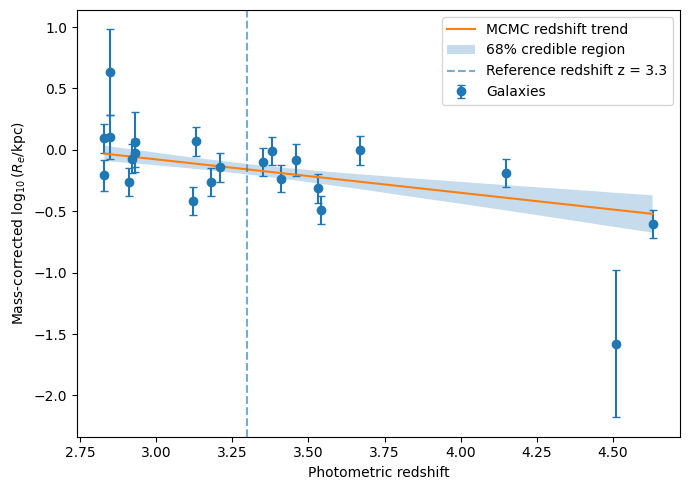

In [12]:
# Section 5: Main redshift result figure

# Remove the fitted stellar-mass dependence from each galaxy
mass_corrected_logRe = (y - b_med_full * (x - 10.7))

# Include radius uncertainty and propagated stellar-mass uncertainty
mass_corrected_err = np.sqrt(yerr**2 + (b_med_full * mass_err)**2)

# Create a smooth redshift range for the fitted relation
z_line = np.linspace(z.min(), z.max(), 200)

# Median fitted redshift relation
redshift_line = (a_med_full + c_med_full * (z_line - 3.3))

# Build a 68% credible region using posterior samples
redshift_model_samples = []

for a_s, c_s in zip(a_samples_full[::50], c_samples_full[::50]):
    redshift_model_samples.append(a_s + c_s * (z_line - 3.3))

redshift_model_samples = np.array(redshift_model_samples)
redshift_lower = np.percentile(redshift_model_samples, 16, axis=0)
redshift_upper = np.percentile(redshift_model_samples, 84, axis=0)

# Plot
plt.figure(figsize=(7, 5))

plt.errorbar(
    z,
    mass_corrected_logRe,
    yerr=mass_corrected_err,
    fmt="o",
    capsize=3,
    label="Galaxies")

plt.plot(
    z_line,
    redshift_line,
    label="MCMC redshift trend")

plt.fill_between(
    z_line,
    redshift_lower,
    redshift_upper,
    alpha=0.25,
    label="68% credible region")

plt.axvline(
    3.3,
    linestyle="--",
    alpha=0.6,
    label="Reference redshift z = 3.3")

plt.xlabel("Photometric redshift")
plt.ylabel(r"Mass-corrected $\log_{10}(R_e/\mathrm{kpc})$")

plt.legend()
plt.tight_layout()
plt.show()

Rest-frame wavelength range sampled by F277W:
0.492 to 0.723 microns


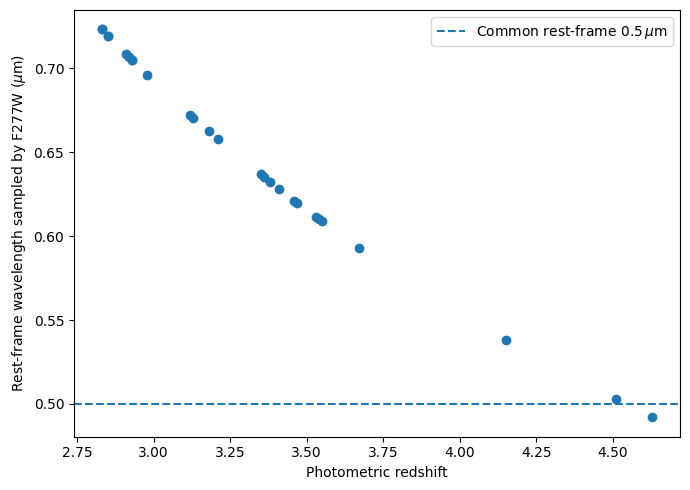


Number of galaxies used in gamma analysis:
25


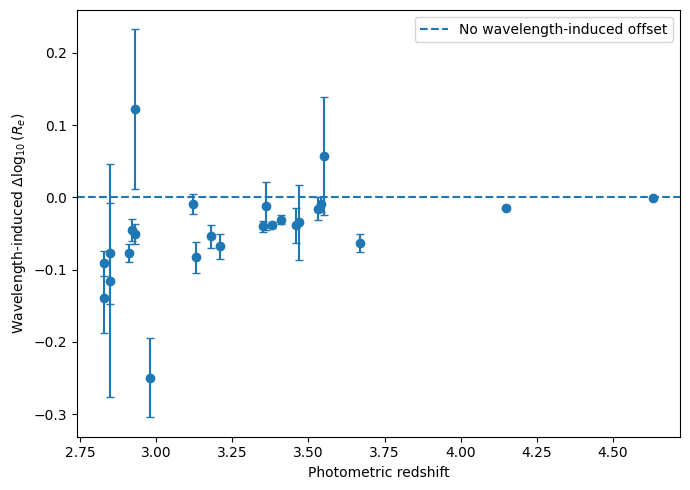

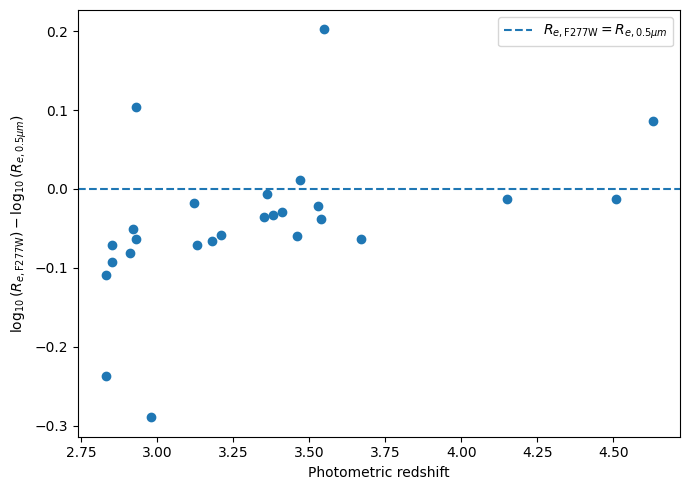


Median gamma:
-0.380

Median wavelength-induced log-radius offset:
-0.040

Range of wavelength-induced log-radius offsets:
-0.250 to 0.122

Median F277W / rest-frame 0.5 micron radius:
0.902

Median directly observed log-radius difference:
-0.045


In [14]:
# Section 6: Rest-frame wavelength

# F277W is centred at about 2.77 microns
lambda_F277W = 2.77

# Calculate the rest-frame wavelength sampled by F277W
df["lambda_rest_F277W_um"] = (lambda_F277W / (1 + df["z_phot"])) # for each galaxy

print("Rest-frame wavelength range sampled by F277W:")
print(f'{df["lambda_rest_F277W_um"].min():.3f}', "to",
      f'{df["lambda_rest_F277W_um"].max():.3f}', "microns")

# Plot the rest-frame wavelength sampled by F277W
plt.figure(figsize=(7, 5))

plt.scatter(
    df["z_phot"],
    df["lambda_rest_F277W_um"])

plt.axhline(
    0.5,
    linestyle="--",
    label=r"Common rest-frame $0.5\,\mu$m")

plt.xlabel("Photometric redshift")
plt.ylabel(r"Rest-frame wavelength sampled by F277W ($\mu$m)")

plt.legend()
plt.tight_layout()
plt.show()

# Exclude ID 185 only from the gamma analysis
gamma_df = df[(df["ID"] != 185) & df["gamma"].notna() & df["gamma_err"].notna()].copy()

print("\nNumber of galaxies used in gamma analysis:")
print(len(gamma_df))

# Calculate the wavelength induced size offset using gamma
gamma_df["delta_logRe_gamma"] = (gamma_df["gamma"] * np.log10(gamma_df["lambda_rest_F277W_um"] / 0.5))

# Uncertainty in gamma
gamma_df["delta_logRe_gamma_err"] = (np.abs(np.log10(gamma_df["lambda_rest_F277W_um"] / 0.5))* gamma_df["gamma_err"])

# Plot the expected wavelength-induced size offset
plt.figure(figsize=(7, 5))

plt.errorbar(
    gamma_df["z_phot"],
    gamma_df["delta_logRe_gamma"],
    yerr=gamma_df["delta_logRe_gamma_err"],
    fmt="o",
    capsize=3)

plt.axhline(
    0,
    linestyle="--",
    label="No wavelength-induced offset")

plt.xlabel("Photometric redshift")
plt.ylabel(r"Wavelength-induced $\Delta \log_{10}(R_e)$")

plt.legend()
plt.tight_layout()
plt.show()


# Directly compare F277W radius with the common 0.5 micron radius
df["logRe_F277W"] = np.log10(df["Re_F277W_kpc"])

df["delta_logRe_observed"] = (df["logRe_F277W"] - df["logRe_05um"])

df["Re_ratio_F277W_to_05um"] = (df["Re_F277W_kpc"] / df["Re_05um_kpc"])

# Supporting plot
plt.figure(figsize=(7, 5))

plt.scatter(
    df["z_phot"],
    df["delta_logRe_observed"])

plt.axhline(
    0,
    linestyle="--",
    label=r"$R_{e,\mathrm{F277W}} = R_{e,0.5\mu m}$")

plt.xlabel("Photometric redshift")
plt.ylabel(r"$\log_{10}(R_{e,\mathrm{F277W}})"r" - \log_{10}(R_{e,0.5\mu m})$")

plt.legend()
plt.tight_layout()
plt.show()


# Print the summary values
print("\nMedian gamma:")
print(f'{np.median(gamma_df["gamma"]):.3f}')

print("\nMedian wavelength-induced log-radius offset:")
print(f'{np.median(gamma_df["delta_logRe_gamma"]):.3f}')

print("\nRange of wavelength-induced log-radius offsets:")
print(f'{gamma_df["delta_logRe_gamma"].min():.3f}', "to",
    f'{gamma_df["delta_logRe_gamma"].max():.3f}')

print("\nMedian F277W / rest-frame 0.5 micron radius:")
print(f'{np.median(df["Re_ratio_F277W_to_05um"]):.3f}')

print("\nMedian directly observed log-radius difference:")
print(f'{np.median(df["delta_logRe_observed"]):.3f}')

In [15]:
# Section 7: Final results

print("Final project results")

print("\nSample")
print("Full catalogue:", len(df))
print("Main fitting sample:", len(fit_df))


print("\nMass-only MCMC fit")
print(f"a = {a_med:.3f} "f"-{a_low:.3f} +{a_high:.3f}")
print(f"b = {b_med:.3f} "f"-{b_low:.3f} +{b_high:.3f}")
print(f"Intrinsic scatter = {s_med:.3f} "f"-{s_low:.3f} +{s_high:.3f}")


print("\nMass + redshift MCMC fit")
print(f"a = {a_med_full:.3f} "f"-{a_low_full:.3f} +{a_high_full:.3f}")
print(f"b = {b_med_full:.3f} "f"-{b_low_full:.3f} +{b_high_full:.3f}")
print(f"c = {c_med_full:.3f} "f"-{c_low_full:.3f} +{c_high_full:.3f}")
print(f"Intrinsic scatter = {s_med_full:.3f} "f"-{s_low_full:.3f} +{s_high_full:.3f}")

print("\nRedshift result")
print(f"95% credible interval for c: "f"{c_025:.3f} to {c_975:.3f}")
print(f"Probability that c < 0: "f"{100 * prob_c_negative:.2f}%")

print("\nRest-frame wavelength test")
print("F277W rest-frame wavelength range:",
      f'{df["lambda_rest_F277W_um"].min():.3f}',"to", f'{df["lambda_rest_F277W_um"].max():.3f}',"microns")

print("Median gamma:",f'{np.median(gamma_df["gamma"]):.3f}')
print("Median wavelength-induced size offset:",f'{np.median(gamma_df["delta_logRe_gamma"]):.3f}',"dex")
print("Median F277W / 0.5 micron radius:",f'{np.median(df["Re_ratio_F277W_to_05um"]):.3f}')

Final project results

Sample
Full catalogue: 26
Main fitting sample: 22

Mass-only MCMC fit
a = -0.145 -0.049 +0.049
b = 0.319 -0.165 +0.162
Intrinsic scatter = 0.190 -0.041 +0.050

Mass + redshift MCMC fit
a = -0.159 -0.043 +0.044
b = 0.530 -0.166 +0.161
c = -0.272 -0.106 +0.099
Intrinsic scatter = 0.139 -0.058 +0.055

Redshift result
95% credible interval for c: -0.499 to -0.075
Probability that c < 0: 99.59%

Rest-frame wavelength test
F277W rest-frame wavelength range: 0.492 to 0.723 microns
Median gamma: -0.380
Median wavelength-induced size offset: -0.040 dex
Median F277W / 0.5 micron radius: 0.902
